In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar `creditsight` sin instalarlo: el código vive en ejemplo/src
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))


# 02 · EDA — qué hay realmente en los datos

El análisis exploratorio no es "hacer gráficos": es **descubrir qué decisiones hay que tomar** antes
de modelar. Cada hallazgo de este notebook termina en una decisión escrita (tabla final), y cada
decisión se convierte después en código con pruebas (`src/creditsight/data/`).

Preguntas que guían el EDA:

1. ¿Cuál es la **unidad de análisis**? ¿Qué representa una fila?
2. ¿Cómo está el **objetivo**? ¿Está balanceado?
3. ¿Qué tan **sucios** están los datos y de qué manera?
4. ¿Qué variables **deberían ser estables** y no lo son?
5. ¿Hay algo que **suene a fuga** de información?

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from creditsight.config import CLASSES, TARGET
from creditsight.data.cleaning import PLAUSIBLE_RANGE, SENTINELS, TEXT_NUMERIC, _to_number, load_raw

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

raw = load_raw()  # load_raw ya elimina ID, Name y SSN (datos personales): no los miramos ni los mostramos
print(f"{raw.shape[0]:,} filas x {raw.shape[1]} columnas (sin datos personales)")

100,000 filas x 25 columnas (sin datos personales)


## 1. ¿Qué es una fila?

Hay una columna `Customer_ID` y una `Month`. Si cada cliente aparece varias veces, **una fila no es
un cliente: es un cliente en un mes**. Eso cambia cómo se valida un modelo.

In [3]:
per_customer = raw.groupby("Customer_ID").size()
print("Clientes distintos:", f"{raw.Customer_ID.nunique():,}")
print("Filas por cliente:", per_customer.value_counts().to_dict())
print("Meses:", raw.Month.unique().tolist())

Clientes distintos: 12,500
Filas por cliente: {8: 12500}
Meses: ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']


**Hallazgo:** panel balanceado: 12.500 clientes × 8 meses (enero–agosto). La unidad de análisis es
**cliente-mes**.

> Consecuencia: si partimos los datos *por fila*, los meses de un mismo cliente caerían en
> entrenamiento y en prueba a la vez. El modelo "reconocería" al cliente en vez de generalizar. La
> partición se hará **por cliente** (notebook 03 lo demuestra con números).

## 2. El objetivo

,proporción
Credit_Score,
Good,17.8%
Standard,53.2%
Poor,29.0%


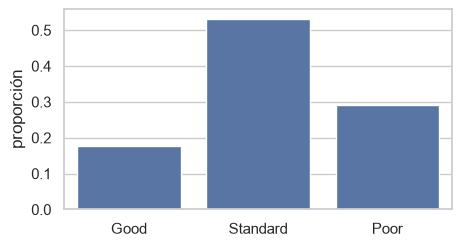

In [4]:
target_share = raw[TARGET].value_counts(normalize=True).reindex(CLASSES[::-1]).rename("proporción")
display(target_share.to_frame().style.format("{:.1%}"))

fig, ax = plt.subplots(figsize=(5, 2.6))
sns.barplot(x=target_share.index, y=target_share.values, ax=ax, color="#4c72b0")
ax.set_ylabel("proporción"); ax.set_xlabel("")
plt.show()

**Hallazgo:** `Standard` 53,2 %, `Poor` 29,0 %, `Good` 17,8 %. Desbalance moderado. Predecir siempre
`Standard` acierta el 53 %: por eso **accuracy no sirve** como métrica.

¿La etiqueta es una propiedad del cliente o del mes?

In [5]:
distinct_labels = raw.groupby("Customer_ID")[TARGET].nunique()
share = distinct_labels.value_counts(normalize=True).sort_index()
print("Clientes según cuántas etiquetas distintas tienen en los 8 meses:")
display(share.rename("proporción de clientes").to_frame().style.format("{:.1%}"))

Clientes según cuántas etiquetas distintas tienen en los 8 meses:


,proporción de clientes
Credit_Score,
1,41.7%
2,58.1%
3,0.2%


**Hallazgo:** el **58 %** de los clientes cambia de etiqueta entre meses. La etiqueta es del
*cliente-mes*, no del cliente. Hay que predecir la etiqueta del mes con la información disponible
en ese mes.

## 3. Datos sucios: qué hay dentro de las columnas

Varias columnas numéricas llegaron como texto. Eso casi siempre significa que hay basura mezclada.
Medimos **qué tipo** de basura y **cuánta** hay en cada columna.

In [6]:
rows = []
for col in TEXT_NUMERIC:
    s = raw[col].dropna().astype(str)
    sentinel = s.isin(SENTINELS)
    trailing = s.str.endswith("_") & ~sentinel
    rows.append({
        "columna": col,
        "centinela (_, __10000__...)": sentinel.mean(),
        "número con '_' sobrante": trailing.mean(),
        "vacío original": raw[col].isna().mean(),
    })
dirt = pd.DataFrame(rows).set_index("columna")
dirt.style.format("{:.1%}").background_gradient(cmap="Reds", axis=None)

,"centinela (_, __10000__...)",número con '_' sobrante,vacío original
columna,,,
Age,0.0%,4.9%,0.0%
Annual_Income,0.0%,7.0%,0.0%
Num_of_Loan,0.0%,4.8%,0.0%
Num_of_Delayed_Payment,0.0%,3.0%,7.0%
Changed_Credit_Limit,2.1%,0.0%,0.0%
Outstanding_Debt,0.0%,1.0%,0.0%
Amount_invested_monthly,4.5%,0.0%,4.5%
Monthly_Balance,0.0%,0.0%,1.2%


In [7]:
# Ejemplos concretos de lo que hay que arreglar
for col in ["Age", "Changed_Credit_Limit", "Amount_invested_monthly", "Monthly_Balance"]:
    bad = raw[col].dropna().astype(str)
    bad = bad[bad.str.contains(r"[^0-9.\-]")]
    print(f"{col:26s}", bad.value_counts().head(3).to_dict())
for col in ["Occupation", "Credit_Mix", "Payment_Behaviour"]:
    top = raw[col].value_counts()
    suspicious = [v for v in top.index if v in SENTINELS]
    print(f"{col:26s} valores centinela: {suspicious} ({raw[col].isin(SENTINELS).mean():.1%})")

Age                        {'24_': 161, '38_': 161, '29_': 160}
Changed_Credit_Limit       {'_': 2091}
Amount_invested_monthly    {'__10000__': 4305}
Monthly_Balance            {'__-333333333333333333333333333__': 9}
Occupation                 valores centinela: ['_______'] (7.1%)
Credit_Mix                 valores centinela: ['_'] (20.2%)
Payment_Behaviour          valores centinela: ['!@9#%8'] (7.6%)


**Hallazgos:**

- Números con un guion bajo pegado (`'23_'`): se arreglan quitando el `_`.
- **Centinelas** (`'_'`, `'_______'`, `'!@9#%8'`) y, sobre todo, **`'__10000__'`**: 4.305 filas de
  `Amount_invested_monthly` con exactamente el mismo valor. Un valor repetido tantas veces no es un
  dato, es un marcador de "no disponible".
- Los centinelas **no son vacíos reales**: hay que convertirlos a vacío antes de cualquier cálculo.

## 4. Valores imposibles

Quitado el guion bajo, ¿hay valores que no pueden ser reales?

In [8]:
num = pd.DataFrame({c: _to_number(raw[c]) for c in TEXT_NUMERIC})
for c in ["Num_Bank_Accounts", "Num_Credit_Card", "Interest_Rate", "Num_Credit_Inquiries", "Total_EMI_per_month"]:
    num[c] = raw[c]
quant = num[list(PLAUSIBLE_RANGE)].quantile([0.5, 0.9, 0.95, 0.97, 0.99, 1.0]).T
quant.columns = ["mediana", "p90", "p95", "p97", "p99", "máximo"]
quant.round(1)

,mediana,p90,p95,p97,p99,máximo
Age,33.0,50.0,53.0,55.0,4112.07,8698.0
Annual_Income,37578.61,113085.87,134533.32,149616.12,179987.28,24198062.0
Num_Bank_Accounts,6.0,9.0,10.0,10.0,445.01,1798.0
Num_Credit_Card,5.0,9.0,10.0,10.0,849.0,1499.0
Interest_Rate,13.0,29.0,33.0,34.0,2865.01,5797.0
Num_of_Loan,3.0,7.0,8.0,9.0,9.0,1496.0
Num_of_Delayed_Payment,14,21,24,25,27,4397
Num_Credit_Inquiries,6.0,12.0,13.0,15.0,1109.28,2597.0
Total_EMI_per_month,69.249473,285.631602,437.012753,4655.15,56125.3,82331.0


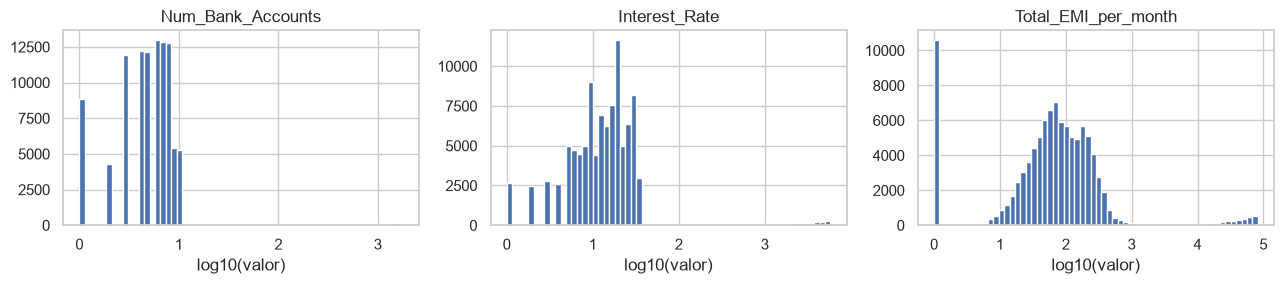

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, col in zip(axes, ["Num_Bank_Accounts", "Interest_Rate", "Total_EMI_per_month"]):
    values = num[col].dropna()
    ax.hist(np.log10(values.clip(lower=1)), bins=60, color="#4c72b0")
    ax.set_title(col); ax.set_xlabel("log10(valor)")
plt.tight_layout(); plt.show()

In [10]:
caps = {"Num_Bank_Accounts": 11, "Num_Credit_Card": 11, "Interest_Rate": 34, "Num_Credit_Inquiries": 17,
        "Total_EMI_per_month": 2000, "Num_of_Delayed_Payment": 28}
out = pd.DataFrame({
    "tope plausible": pd.Series(caps),
    "% sobre el tope": pd.Series({c: (num[c] > t).mean() for c, t in caps.items()}),
})
out["% negativos"] = pd.Series({c: (num[c] < 0).mean() for c in caps})
out.style.format({"% sobre el tope": "{:.1%}", "% negativos": "{:.1%}"})

,tope plausible,% sobre el tope,% negativos
Num_Bank_Accounts,11,1.3%,0.0%
Num_Credit_Card,11,2.3%,0.0%
Interest_Rate,34,2.0%,0.0%
Num_Credit_Inquiries,17,1.7%,0.0%
Total_EMI_per_month,2000,3.1%,0.0%
Num_of_Delayed_Payment,28,0.8%,0.7%


**Hallazgo:** los percentiles suben de forma normal hasta ~p95–p97 y luego **se disparan**
(`Num_Bank_Accounts` pasa de 10 a 445; `Interest_Rate` de 34 a 2.865; edades de 55 a 4.112). Es un
salto claro, no una cola natural: son valores corruptos. También hay **negativos imposibles**
(edad −500, préstamos −100).

Los topes de la tabla salen de ese salto y se usan en `PLAUSIBLE_RANGE`. Lo que sale del rango
se marca como **vacío**, no se borra la fila: perder el 3 % de las filas por una columna sería peor
que imputar ese dato.

## 5. ¿Qué debería ser estable y no lo es?

Edad, ocupación, ingreso o número de tarjetas de un cliente **no cambian en 8 meses**. Si en los
datos cambian, el cambio es ruido. Lo comprobamos: ¿cuántos clientes tienen más de un valor *válido*?

In [11]:
def valid(col):
    s = _to_number(raw[col]) if col in TEXT_NUMERIC else raw[col].copy()
    if col in PLAUSIBLE_RANGE:
        low, high = PLAUSIBLE_RANGE[col]
        s = s.where(s.between(low, high))
    if s.dtype == object or str(s.dtype) == "str":
        s = s.where(~s.isin(SENTINELS))
    return s

stable_candidates = ["Age", "Occupation", "Annual_Income", "Num_Bank_Accounts", "Num_Credit_Card",
                     "Interest_Rate", "Num_of_Loan", "Credit_Mix"]
rows = []
for col in stable_candidates:
    before = raw.groupby("Customer_ID")[col].nunique().gt(1).mean()
    after = valid(col).groupby(raw["Customer_ID"]).nunique().gt(1).mean()
    rows.append({"columna": col, "clientes con >1 valor (crudo)": before, "clientes con >1 valor (solo válidos)": after})
stab = pd.DataFrame(rows).set_index("columna")
stab.style.format("{:.1%}")

,clientes con >1 valor (crudo),clientes con >1 valor (solo válidos)
columna,,
Age,77.4%,57.6%
Occupation,44.4%,0.0%
Annual_Income,48.2%,0.0%
Num_Bank_Accounts,12.2%,2.4%
Num_Credit_Card,19.0%,2.5%
Interest_Rate,15.3%,0.0%
Num_of_Loan,53.2%,0.0%
Credit_Mix,83.8%,0.0%


In [12]:
age = valid("Age").astype(float)
spread = age.groupby(raw["Customer_ID"]).agg(lambda s: s.max() - s.min())
steps = age.groupby(raw["Customer_ID"]).diff().dropna()
print("Diferencia entre la edad máxima y mínima de cada cliente:", spread.value_counts().sort_index().head(4).to_dict(), "... y", int((spread > 2).sum()), "clientes con más de 2 años de diferencia")
print("Cambio de edad entre meses consecutivos:", steps.value_counts().head(4).to_dict())

Diferencia entre la edad máxima y mínima de cada cliente: {0.0: 5297, 1.0: 7198, 44.0: 1, 63.0: 1} ... y 5 clientes con más de 2 años de diferencia
Cambio de edad entre meses consecutivos: {0.0: 75822, 1.0: 6877, 68.0: 2, -68.0: 2}


**La edad sube exactamente +1** en 6.877 pasos mensuales: es el cumpleaños dentro de los 8 meses, una
variación **real**, no ruido. Solo 5 clientes tienen una edad corrupta que sigue dentro del rango
(por ejemplo 95 en un mes y 24 en los demás). Usar el valor más frecuente del cliente comete como
mucho un error de un año, que no importa para el modelo, y arregla esos 5 casos.

**Hallazgo clave:** al descartar los valores corruptos, casi todas las variables estables **dejan de
variar** (ocupación, ingreso, tasa de interés, número de préstamos y `Credit_Mix` caen a 0 %). La
diferencia entre meses era **ruido**. Eso habilita una reparación mucho mejor que imputar con la
mediana global: **usar el valor válido más frecuente del propio cliente**, que solo mira filas del
mismo cliente (no cruza particiones, no hay fuga).

Dos excepciones que conviene entender, no ignorar: la **edad** (57,6 %) y, en menor medida, las
**cuentas bancarias** y **tarjetas** (~2,5 %). Miremos la edad más de cerca.

Dos casos especiales:

- **`Credit_Mix`**: parecía cambiar en el 84 % de los clientes, pero eran los `_` (perdidos). Es
  **constante por cliente**.
- **`Annual_Income`** y **`Monthly_Inhand_Salary`**: el sueldo mensual es casi el ingreso anual / 12.

## 6. Dos columnas que no son lo que parecen

In [13]:
loan_empty = raw["Type_of_Loan"].isna()
print("Type_of_Loan vacío   <->   Num_of_Loan == 0")
display(pd.crosstab(loan_empty.rename("Type_of_Loan vacío"), (valid("Num_of_Loan") == 0).rename("Num_of_Loan == 0")))

hist = raw["Credit_History_Age"].str.extract(r"(\d+)\s+Years?\s+and\s+(\d+)\s+Months?").astype(float)
months = (hist[0] * 12 + hist[1]).groupby(raw["Customer_ID"]).diff().dropna()
print("\nDiferencia de antigüedad crediticia entre meses consecutivos:", months.value_counts().to_dict())
print("Antigüedad vacía:", f"{raw['Credit_History_Age'].isna().mean():.1%}")

Type_of_Loan vacío   <->   Num_of_Loan == 0


Num_of_Loan == 0,False,True
Type_of_Loan vacío,,
False,84722,0
True,0,10930



Diferencia de antigüedad crediticia entre meses consecutivos: {1.0: 72373}
Antigüedad vacía: 9.0%


**Hallazgos:**

- `Type_of_Loan` vacío **coincide exactamente** con `Num_of_Loan == 0` en todas las filas donde
  `Num_of_Loan` es válido (la tabla excluye las 4.348 con valor corrupto): significa "sin préstamos",
  no "dato faltante". No se imputa; se interpreta.
- La antigüedad crediticia sube **exactamente un mes por mes** (72.373 de 72.373 diferencias). Los
  vacíos (9 %) **no hace falta imputarlos: se reconstruyen** con la regla.

## 7. ¿Algo que suene a fuga?

`Credit_Mix` (`Bad`/`Standard`/`Good`) se parece sospechosamente al objetivo.

In [14]:
mix = raw["Credit_Mix"].where(~raw["Credit_Mix"].isin(SENTINELS))
ct = pd.crosstab(mix, raw[TARGET], normalize="index").reindex(columns=CLASSES)
ct.style.format("{:.0%}").background_gradient(cmap="Blues", axis=None)

Credit_Score,Poor,Standard,Good
Credit_Mix,,,
Bad,60%,38%,2%
Good,16%,35%,49%
Standard,22%,73%,6%


**Hallazgo:** `Credit_Mix = Bad` → 60 % `Poor`; `Credit_Mix = Good` → 49 % `Good`. Está muy
asociado, pero **no es el objetivo disfrazado**: aun con `Bad`, el 38 % es `Standard`. Podría ser
una señal legítima (un buró de crédito lo calcula) o una fuga si se conoce *después* de calificar.

> **No lo descartamos por intuición: lo medimos.** En el notebook 04 el modelo se entrena **con y
> sin** `Credit_Mix` y la decisión se toma con la métrica de negocio.

## 8. Un vistazo a la señal

Con los valores corruptos descartados, ¿qué variables parecen separar las clases?

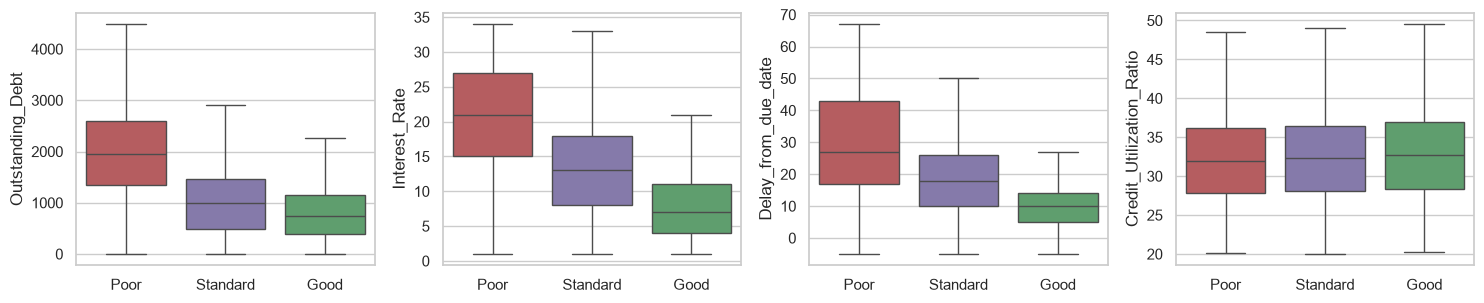

In [15]:
view = pd.DataFrame({
    "Outstanding_Debt": _to_number(raw["Outstanding_Debt"]),
    "Interest_Rate": valid("Interest_Rate"),
    "Delay_from_due_date": raw["Delay_from_due_date"],
    "Credit_Utilization_Ratio": raw["Credit_Utilization_Ratio"],
    TARGET: pd.Categorical(raw[TARGET], categories=CLASSES, ordered=True),
})
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, col in zip(axes, view.columns[:-1]):
    sns.boxplot(data=view, x=TARGET, y=col, ax=ax, palette=["#c44e52", "#8172b2", "#55a868"], showfliers=False)
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Hallazgo:** deuda pendiente, tasa de interés y retraso en pagos separan bien las clases (`Poor` con
más deuda, tasa y retraso). La utilización del crédito casi no separa. Es el tipo de señal que un
modelo puede aprovechar.

## 9. Decisiones que salen del EDA

Cada fila se convierte en código con pruebas en `src/creditsight/data/cleaning.py`.

| # | Hallazgo | Decisión |
|---|---|---|
| 1 | `Name`, `SSN`, `ID` son datos personales (sintéticos, pero se tratan como reales) | Se eliminan al cargar; nunca llegan al modelo |
| 2 | La unidad de análisis es cliente-mes; 8 filas por cliente | Todas las particiones y la validación cruzada son **por cliente** |
| 3 | Accuracy da 53 % sin modelo | Métrica = **costo esperado** con matriz de costos; F1 macro y recall de `Poor` como controles |
| 4 | Centinelas (`_`, `__10000__`, `!@9#%8`) y números con `_` sobrante | Centinelas → vacío; se quita el `_` y se convierte a número |
| 5 | Salto brusco tras p95–p97 y negativos imposibles | Valores fuera de un rango plausible → vacío (sin borrar filas) |
| 6 | Variables estables varían solo por ruido | Se reparan con el valor válido más frecuente **del propio cliente** |
| 7 | `Credit_Mix` es constante por cliente (los `_` eran perdidos) | Se repara igual; se medirá su aporte con y sin ella |
| 8 | `Type_of_Loan` vacío = sin préstamos | No se imputa; se interpreta como "ningún préstamo" |
| 9 | Antigüedad crediticia +1 mes por mes | Los vacíos se **reconstruyen** con la regla, no se imputan |
| 10 | Sueldo mensual ≈ ingreso anual / 12 | Los vacíos se rellenan con la mediana del cliente |

**Siguiente:** `03_preprocesamiento.ipynb` implementa estas decisiones y demuestra por qué la
partición debe ser por cliente.